[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DevDeepakBhattarai/ml-notebooks-2023/blob/main/CNN.ipynb)

In [ ]:
from tensorflow.keras.layers import Conv2D , Dense , Flatten , MaxPooling2D
from tensorflow.keras import Sequential
from tensorflow.keras.datasets import mnist
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

In [ ]:
(X_train, y_train), (X_test,y_text) = mnist.load_data()


In [ ]:
model =Sequential([
    Conv2D(6,(3,3),input_shape=(28,28,1),activation="relu"),
    MaxPooling2D((2,2)),
    Conv2D(6,(3,3),activation="relu"),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(120, activation='relu'),
    Dense(84,activation='relu'),
    Dense(10,activation="softmax")]
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 6)         60        
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 6)         0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 6)         330       
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 6)           0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 150)               0         
                                                                 
 dense (Dense)               (None, 120)               1

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.01),loss="sparse_categorical_crossentropy")

In [ ]:
model.fit(X_train,y_train,epochs=100,batch_size=1000)

Epoch 1/100
60/60 [==============================] - 8s 10ms/step - loss: 2.9365
Epoch 2/100
60/60 [==============================] - 1s 11ms/step - loss: 0.4472
Epoch 3/100
60/60 [==============================] - 1s 10ms/step - loss: 0.2799
Epoch 4/100
60/60 [==============================] - 1s 9ms/step - loss: 0.2101
Epoch 5/100
60/60 [==============================] - 0s 8ms/step - loss: 0.1691
Epoch 6/100
60/60 [==============================] - 0s 7ms/step - loss: 0.1424
Epoch 7/100
60/60 [==============================] - 1s 8ms/step - loss: 0.1256
Epoch 8/100
60/60 [==============================] - 0s 8ms/step - loss: 0.1132
Epoch 9/100
60/60 [==============================] - 0s 8ms/step - loss: 0.1038
Epoch 10/100
60/60 [==============================] - 0s 8ms/step - loss: 0.0969
Epoch 11/100
60/60 [==============================] - 0s 7ms/step - loss: 0.0939
Epoch 12/100
60/60 [==============================] - 0s 6ms/step - loss: 0.0812
Epoch 13/100
60/60 [==============

1/1 [==============================] - 0s 24ms/step


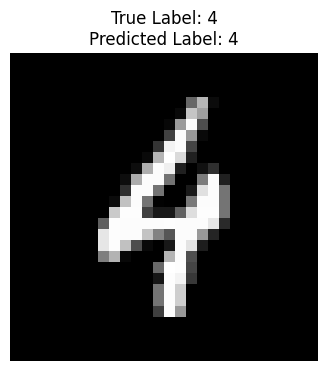

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming you already have your model and test data loaded and preprocessed

# Load a sample test image (you can change the index as needed)
sample_index =3672
input_image = X_test[sample_index].reshape(-1,28,28,1)
true_label = y_text[sample_index]

# Make a prediction for the sample image
predicted_probabilities = model.predict(input_image)
predicted_class = np.argmax(predicted_probabilities)

# Display the input image
plt.figure(figsize=(4, 4))
plt.imshow(input_image[0, :, :, 0], cmap='gray')
plt.title(f"True Label: {true_label}\nPredicted Label: {predicted_class}")
plt.axis('off')
plt.show()


In [ ]:
print(np.argmax(model.predict(X_test[313].reshape(-1,28,28,1))),y_text[313])

1/1 [==============================] - 0s 42ms/step
3 3


### Testing if image can be scaled down with Pooling only

(1440, 2560, 3)


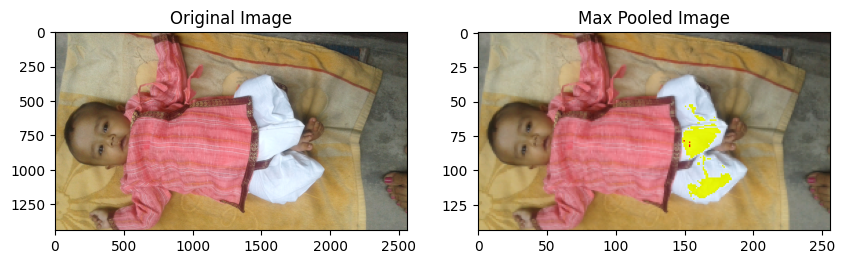

In [29]:
import numpy as np
from skimage import io
from tensorflow.keras.layers import AvgPool2D  # Import MaxPooling2D
import matplotlib.pyplot as plt

# Load an example image (you can replace this with your own image)
image = io.imread('./img.jpg')  # Replace with your image path
print(image.shape)

# Define the pooling size (e.g., 2x2)
pooling_size = (10, 10)

# Create a MaxPooling2D layer
pooling_layer = AvgPool2D(pool_size=pooling_size)

# Add a batch dimension and preprocess the image
image = image.reshape(1, image.shape[0], image.shape[1], -1).astype(np.float32) / 225.0

# Apply the MaxPooling2D layer to the input image
max_pooled_image = pooling_layer(image)
max_pooled_image = (max_pooled_image[0] * 255).numpy().astype(np.uint8)

# Display the original image and pooled images
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title('Original Image')
plt.imshow(image[0])  # Remove the extra dimension

plt.subplot(1, 2, 2)
plt.title('Max Pooled Image')
plt.imshow(max_pooled_image)  # Convert back to uint8 for display

plt.show()
